# Notebook 15 - Diagnostik Noise pada Label Klasifikasi (Horizon 5 Hari)

Sebelum training, notebook ini mengukur seberapa besar **noise** yang
tersembunyi di skema pelabelan biner saat ini
(`Close[t+HORIZON] > Close[t]`, lihat
`models/lstm/notebook07_common.py:281`). Hipotesis: return 5-hari yang
sangat kecil (mendekati 0%) dilabel "naik"/"turun" dengan bobot yang sama
kuatnya dengan return besar, padahal arahnya nyaris acak (murni price
noise, bukan sinyal).

Data dipakai dari `pipeline.feature_engineering.dataset_builder.load_return_features()`
- fitur return + `Close` level resmi, SAMA sumber dengan Notebook 13/14
(tidak perlu rerun FinBERT scoring).

**Yang diukur:**
1. Distribusi forward-return horizon-5 & proporsi di "zona nol" (deadband)
2. Signal-to-noise kasar: return aktual vs ekspektasi random walk
3. Label flip sensitivity terhadap threshold epsilon
4. Autokorelasi (ACF) return harian & horizon-5
5. Rekomendasi skema deadband/triple-barrier

## Setup

In [9]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("E:/forecasting_index_snp500/stock_prediction")
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

from pipeline.feature_engineering.dataset_builder import load_return_features

HORIZON = 5  # sama dengan skema label produksi (notebook07_common.py, notebook13/14)
OUT_DIR = ROOT / "notebooks" / "outputs" / "notebook15"
OUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

## Bagian 1 - Load Data & Hitung Forward Return Horizon-5

`load_return_features()` mengembalikan `Close` level resmi (bukan fitur
model, hanya dipakai menghitung label). Forward return dihitung sebagai
`Close[t+HORIZON] / Close[t] - 1` - besaran yang menentukan label
naik/turun saat ini.

In [10]:
df = load_return_features()
df = df.sort_values("Date").reset_index(drop=True)

df["fwd_return_h5"] = df["Close"].shift(-HORIZON) / df["Close"] - 1.0
df["label_binary"] = (df["Close"].shift(-HORIZON) > df["Close"]).astype("Int64")

df_valid = df.dropna(subset=["fwd_return_h5"]).reset_index(drop=True)

print(f"Total baris (setelah drop NaN horizon): {len(df_valid):,}")
print(f"Rentang tanggal: {df_valid['Date'].min().date()} s/d {df_valid['Date'].max().date()}")
print(f"\nDistribusi label saat ini (naik=1 / turun=0):")
print(df_valid["label_binary"].value_counts(normalize=True).round(4))
df_valid[["Date", "Close", "fwd_return_h5", "label_binary"]].head()

Total baris (setelah drop NaN horizon): 1,521
Rentang tanggal: 2018-01-03 s/d 2024-02-26

Distribusi label saat ini (naik=1 / turun=0):
label_binary
1   0.606800
0   0.393200
Name: proportion, dtype: Float64


,Date,Close,fwd_return_h5,label_binary
0,2018-01-03,"2,713.060059",0.012963,1
1,2018-01-04,"2,723.989990",0.022853,1
2,2018-01-05,"2,743.149902",0.012128,1
3,2018-01-08,"2,747.709961",0.019962,1
4,2018-01-09,"2,751.290039",0.016988,1


## Bagian 2 - Distribusi Forward Return & Zona "Deadband"

Histogram return horizon-5. Area sempit di sekitar 0% adalah kandidat
label ambigu: pergerakan sekecil itu nyaris tidak bisa dibedakan dari
noise harian, tapi tetap dipaksa jadi label "naik" atau "turun" tegas.

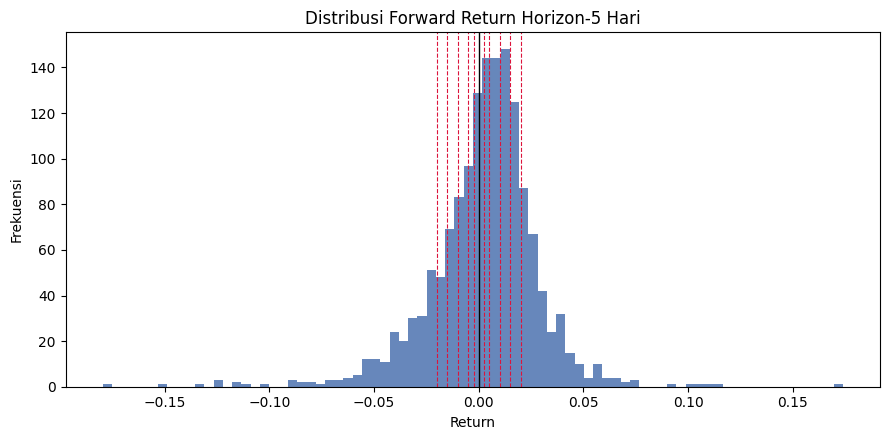

Proporsi sampel di dalam deadband +-theta (kandidat label ambigu/noise):
  theta=0.25% -> 10.06% sampel berada di zona nol
  theta=0.50% -> 18.80% sampel berada di zona nol
  theta=1.00% -> 36.69% sampel berada di zona nol
  theta=1.50% -> 52.79% sampel berada di zona nol
  theta=2.00% -> 66.01% sampel berada di zona nol


In [11]:
DEADBAND_CANDIDATES = [0.0025, 0.005, 0.01, 0.015, 0.02]  # 0.25% s/d 2%

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df_valid["fwd_return_h5"], bins=80, color="#4c72b0", alpha=0.85)
for theta in DEADBAND_CANDIDATES:
    ax.axvline(theta, color="crimson", linestyle="--", linewidth=0.8)
    ax.axvline(-theta, color="crimson", linestyle="--", linewidth=0.8)
ax.axvline(0, color="black", linewidth=1)
ax.set_title(f"Distribusi Forward Return Horizon-{HORIZON} Hari")
ax.set_xlabel("Return")
ax.set_ylabel("Frekuensi")
fig.tight_layout()
fig.savefig(OUT_DIR / "hist_forward_return.png", dpi=120)
plt.show()

print("Proporsi sampel di dalam deadband +-theta (kandidat label ambigu/noise):")
for theta in DEADBAND_CANDIDATES:
    in_band = (df_valid["fwd_return_h5"].abs() <= theta).mean()
    print(f"  theta={theta:5.2%} -> {in_band:6.2%} sampel berada di zona nol")

## Bagian 3 - Signal-to-Noise Kasar

Kalau harga murni random walk, `std(return horizon-N)` seharusnya sekitar
`sqrt(N) * std(return harian)` (skala volatilitas kumulatif tanpa
prediktabilitas tambahan). Semakin dekat rasio aktual/ekspektasi ke 1.0,
semakin dominan noise (semakin sedikit sinyal predictable yang bisa
dipelajari model) pada horizon tersebut.

In [12]:
ret_1d = df_valid["ret_close"].dropna()
std_1d = ret_1d.std()
std_h5_expected = std_1d * np.sqrt(HORIZON)
std_h5_actual = df_valid["fwd_return_h5"].std()

snr_ratio = std_h5_actual / std_h5_expected

print(f"std return harian                     : {std_1d:.6f}")
print(f"std horizon-{HORIZON} EKSPEKTASI (random walk) : {std_h5_expected:.6f}")
print(f"std horizon-{HORIZON} AKTUAL                   : {std_h5_actual:.6f}")
print(f"rasio aktual/ekspektasi                 : {snr_ratio:.4f}")
print()
if 0.9 <= snr_ratio <= 1.1:
    print("-> Rasio ~1.0: return horizon-5 berperilaku hampir seperti random walk murni.")
    print("   Sedikit bukti struktur/sinyal predictable dari harga sendiri (price noise dominan).")
else:
    print("-> Rasio menyimpang cukup jauh dari 1.0: ada struktur non-random walk (bisa jadi sinyal ATAU regime shift).")

std return harian                     : 0.013004
std horizon-5 EKSPEKTASI (random walk) : 0.029077
std horizon-5 AKTUAL                   : 0.026318
rasio aktual/ekspektasi                 : 0.9051

-> Rasio ~1.0: return horizon-5 berperilaku hampir seperti random walk murni.
   Sedikit bukti struktur/sinyal predictable dari harga sendiri (price noise dominan).


## Bagian 4 - Label Flip Sensitivity

Kalau kita geser threshold pelabelan dari tepat 0 menjadi zona
deadband +-epsilon (observasi di dalam zona dianggap "neutral"/ambigu,
bukan dipaksa naik/turun), berapa persen dari label biner yang selama
ini dipakai ternyata berasal dari pergerakan sekecil epsilon? Persentase
ini adalah ukuran langsung seberapa "rapuh" label saat ini.

In [13]:
EPSILONS = [0.001, 0.0025, 0.005, 0.0075, 0.01, 0.015, 0.02]

flip_rows = []
for eps in EPSILONS:
    in_band = (df_valid["fwd_return_h5"].abs() <= eps)
    flip_rows.append({
        "epsilon": eps,
        "pct_in_deadband": in_band.mean(),
        "n_in_deadband": int(in_band.sum()),
    })

df_flip = pd.DataFrame(flip_rows)
df_flip["pct_in_deadband"] = df_flip["pct_in_deadband"].map(lambda v: f"{v:.2%}")
print("Persentase label saat ini yang berasal dari return sekecil epsilon")
print("(kandidat noise label jika threshold diganti jadi deadband):")
df_flip

Persentase label saat ini yang berasal dari return sekecil epsilon
(kandidat noise label jika threshold diganti jadi deadband):


,epsilon,pct_in_deadband,n_in_deadband
0,0.001000,3.48%,53
1,0.002500,10.06%,153
2,0.005000,18.80%,286
3,0.007500,28.14%,428
4,0.010000,36.69%,558
5,0.015000,52.79%,803
6,0.020000,66.01%,1004


## Bagian 5 - Autokorelasi (ACF) Return Harian & Horizon-5

ACF mendekati 0 di semua lag mengindikasikan deret harga mendekati
random walk (minim struktur temporal yang bisa dipelajari LSTM dari
harga saja). Dibandingkan dengan return horizon-5 (overlapping window)
yang secara konstruksi punya autokorelasi artifisial dari window yang
saling tumpang tindih.

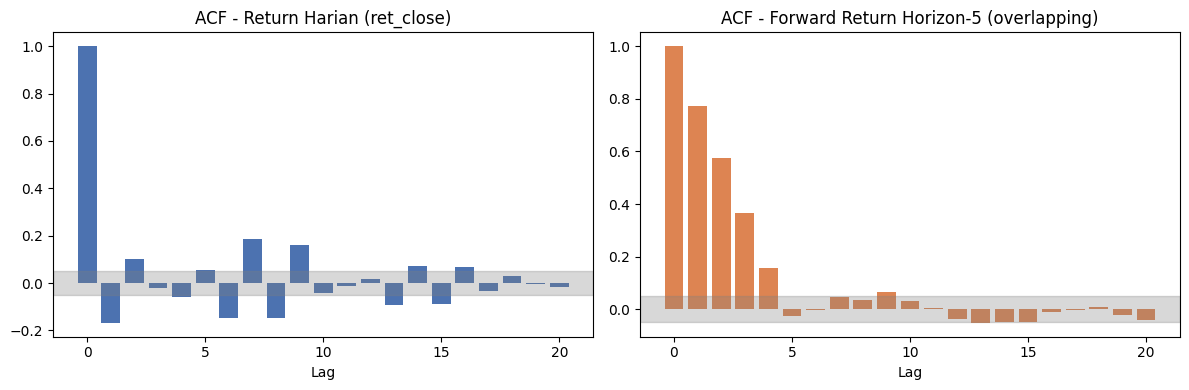

Band abu-abu = interval kepercayaan 95% (+-1.96/sqrt(n)) untuk 'tidak ada autokorelasi'.
Batang yang keluar dari band = autokorelasi signifikan pada lag tsb.


In [14]:
def acf(series: np.ndarray, max_lag: int) -> np.ndarray:
    """ACF manual (numpy only, tanpa dependency statsmodels)."""
    x = np.asarray(series, dtype=float)
    x = x - x.mean()
    denom = np.dot(x, x)
    return np.array([1.0 if lag == 0 else np.dot(x[:-lag], x[lag:]) / denom for lag in range(max_lag + 1)])


MAX_LAG = 20
ci_1d = 1.96 / np.sqrt(len(ret_1d))
ci_h5 = 1.96 / np.sqrt(len(df_valid["fwd_return_h5"].dropna()))

acf_1d = acf(ret_1d.values, MAX_LAG)
acf_h5 = acf(df_valid["fwd_return_h5"].dropna().values, MAX_LAG)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(MAX_LAG + 1), acf_1d, color="#4c72b0")
axes[0].axhspan(-ci_1d, ci_1d, color="grey", alpha=0.3)
axes[0].set_title("ACF - Return Harian (ret_close)")
axes[0].set_xlabel("Lag")

axes[1].bar(range(MAX_LAG + 1), acf_h5, color="#dd8452")
axes[1].axhspan(-ci_h5, ci_h5, color="grey", alpha=0.3)
axes[1].set_title(f"ACF - Forward Return Horizon-{HORIZON} (overlapping)")
axes[1].set_xlabel("Lag")
fig.tight_layout()
fig.savefig(OUT_DIR / "acf_returns.png", dpi=120)
plt.show()

print("Band abu-abu = interval kepercayaan 95% (+-1.96/sqrt(n)) untuk 'tidak ada autokorelasi'.")
print("Batang yang keluar dari band = autokorelasi signifikan pada lag tsb.")

## Bagian 6 - Ringkasan & Rekomendasi Skema Labeling

Ringkasan metrik di atas, plus perbandingan kasar performa label biner
saat ini vs skema deadband (berapa banyak data akan masuk kelas
"neutral" pada tiap kandidat theta) sebagai dasar mendesain skema
pelabelan baru (deadband tetap atau triple-barrier berbasis
volatilitas).

In [15]:
summary = {
    "n_samples": len(df_valid),
    "std_1d": float(std_1d),
    "std_h5_expected_random_walk": float(std_h5_expected),
    "std_h5_actual": float(std_h5_actual),
    "snr_ratio": float(snr_ratio),
    "deadband_scan": [
        {"theta": theta, "pct_in_deadband": float((df_valid["fwd_return_h5"].abs() <= theta).mean())}
        for theta in DEADBAND_CANDIDATES
    ],
}

import json as _json
summary_path = OUT_DIR / "noise_diagnostic_summary.json"
summary_path.write_text(_json.dumps(summary, indent=2), encoding="utf-8")

print("Ringkasan disimpan ke:", summary_path)
for row in summary["deadband_scan"]:
    print(f"  theta={row['theta']:.2%} -> {row['pct_in_deadband']:.2%} data akan jadi kelas 'neutral'")

print()
print("Rekomendasi:")
print("1. Pilih theta deadband (mis. theta = k * rolling_volatility, k~0.5-1.0) alih-alih threshold tetap di 0.")
print("2. Observasi di dalam deadband: buang dari training ATAU jadikan kelas ke-3 ('neutral').")
print("3. Pertimbangkan triple-barrier (Lopez de Prado): upper/lower barrier berbasis volatilitas + vertical barrier=horizon.")
print("4. Karena sinyal OHLCV lemah (lihat Notebook 13, LogReg AUC~0.6), beri bobot label lebih besar pada sentimen (FinBERT) sbg filter kualitas sinyal.")

Ringkasan disimpan ke: E:\forecasting_index_snp500\stock_prediction\notebooks\outputs\notebook15\noise_diagnostic_summary.json
  theta=0.25% -> 10.06% data akan jadi kelas 'neutral'
  theta=0.50% -> 18.80% data akan jadi kelas 'neutral'
  theta=1.00% -> 36.69% data akan jadi kelas 'neutral'
  theta=1.50% -> 52.79% data akan jadi kelas 'neutral'
  theta=2.00% -> 66.01% data akan jadi kelas 'neutral'

Rekomendasi:
1. Pilih theta deadband (mis. theta = k * rolling_volatility, k~0.5-1.0) alih-alih threshold tetap di 0.
2. Observasi di dalam deadband: buang dari training ATAU jadikan kelas ke-3 ('neutral').
3. Pertimbangkan triple-barrier (Lopez de Prado): upper/lower barrier berbasis volatilitas + vertical barrier=horizon.
4. Karena sinyal OHLCV lemah (lihat Notebook 13, LogReg AUC~0.6), beri bobot label lebih besar pada sentimen (FinBERT) sbg filter kualitas sinyal.


## Bagian 7 - Perbandingan Empiris Skema Labeling (Data-Driven)

**Catatan metodologi (revisi):** versi sebelumnya memakai split 70/30 -
test-nya kebetulan mulai 21 April 2022, persis rezim bear market anomali
yang didiagnosis di Notebook 11, sehingga SEMUA skema sama-sama diuji di
test-set "sulit" yang sama dan hasil antar skema jadi kurang bisa
dibandingkan dengan baseline Notebook 13. Di sini split diganti **70/15/15**
(train/val/test), SAMA persis protokol Notebook 13, supaya periode test
match dan perbandingan lebih adil.

**Catatan tujuan (revisi):** AUC tinggi BUKAN tujuan utama di sini. Yang
lebih penting adalah apakah model **benar-benar belajar** dari data - bukan
collapse ke 1 kelas (menebak sama terus, angka accuracy tinggi tapi palsu -
persis masalah yang didiagnosis di Notebook 13 Bagian 9b). Karena itu tiap
skema dilaporkan dengan diagnostik tambahan di luar AUC:
- **std(probabilitas prediksi)** - kalau mendekati 0, model tidak benar-benar
  membedakan sampel (nyaris menebak angka yang sama terus -> tanda collapse)
- **proporsi kelas yang diprediksi** - kalau salah satu kelas nyaris 0%,
  model tidak pernah berani menebak kelas itu
- **val vs test AUC** - kalau rankingnya TIDAK konsisten antara val dan
  test, itu tanda hasil labilnya kebetulan/noise sampling, bukan sinyal asli
  (temuan yang sama persis di Notebook 13 Bagian 10: val_f1_macro tidak bisa
  dipakai memilih seed karena rankingnya acak)

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

FEATURE_COLS = ["ret_open", "ret_high", "ret_low", "ret_close", "ret_volume", "sentiment_mean"]

df_eval = df_valid.dropna(subset=FEATURE_COLS).reset_index(drop=True)
n = len(df_eval)
TRAIN_END = int(n * 0.70)
VAL_END = int(n * 0.85)  # sama persis rasio 70/15/15 Notebook 13

print(f"Total sampel dipakai perbandingan : {n:,}")
print(f"Train : baris 0..{TRAIN_END}       ({df_eval['Date'].iloc[0].date()} s/d {df_eval['Date'].iloc[TRAIN_END-1].date()})")
print(f"Val   : baris {TRAIN_END}..{VAL_END}  ({df_eval['Date'].iloc[TRAIN_END].date()} s/d {df_eval['Date'].iloc[VAL_END-1].date()})")
print(f"Test  : baris {VAL_END}..{n}       ({df_eval['Date'].iloc[VAL_END].date()} s/d {df_eval['Date'].iloc[n-1].date()})")


def _fit_eval(train, split_df, label_col):
    if len(train) < 20 or len(split_df) < 20 or train[label_col].nunique() < 2 or split_df[label_col].nunique() < 2:
        return None

    scaler = StandardScaler().fit(train[FEATURE_COLS])
    X_train = scaler.transform(train[FEATURE_COLS])
    X_split = scaler.transform(split_df[FEATURE_COLS])
    y_train = train[label_col].astype(int).values
    y_split = split_df[label_col].astype(int).values

    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)
    proba = clf.predict_proba(X_split)[:, 1]
    pred = (proba >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_split, pred, labels=[0, 1]).ravel()
    majority_baseline_acc = max(y_split.mean(), 1 - y_split.mean())
    collapse_flag = (pred.mean() in (0.0, 1.0)) or (proba.std() < 0.02)

    return {
        "n": len(split_df),
        "auc": roc_auc_score(y_split, proba),
        "f1_macro": f1_score(y_split, pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_split, pred),
        "majority_baseline_acc": majority_baseline_acc,
        "pred_class1_share": pred.mean(),
        "actual_class1_share": y_split.mean(),
        "std_proba": proba.std(),
        "confusion_tn_fp_fn_tp": f"{tn}/{fp}/{fn}/{tp}",
        "collapse_like": collapse_flag,
    }


def eval_scheme(name: str, df: pd.DataFrame, label_col: str, mask: pd.Series | None = None) -> dict:
    """Fit di TRAIN, evaluasi terpisah di VAL dan TEST (split 70/15/15
    tetap - `mask` cuma memfilter sampel per baris, TIDAK menggeser titik
    potong train/val/test)."""
    d = df.copy()
    d["_split"] = np.where(np.arange(len(d)) < TRAIN_END, "train",
                    np.where(np.arange(len(d)) < VAL_END, "val", "test"))
    if mask is not None:
        d = d[mask].reset_index(drop=True)

    train = d[d["_split"] == "train"]
    val = d[d["_split"] == "val"]
    test = d[d["_split"] == "test"]

    row = {"scheme": name, "n_train": len(train)}
    for split_name, split_df in [("val", val), ("test", test)]:
        r = _fit_eval(train, split_df, label_col)
        if r is None:
            row[f"n_{split_name}"] = len(split_df)
            for k in ["auc", "f1_macro", "balanced_accuracy", "majority_baseline_acc",
                      "pred_class1_share", "actual_class1_share", "std_proba", "collapse_like"]:
                row[f"{split_name}_{k}"] = np.nan
            row[f"{split_name}_confusion_tn_fp_fn_tp"] = "n/a (data tidak cukup)"
        else:
            row[f"n_{split_name}"] = r["n"]
            for k, v in r.items():
                if k != "n":
                    row[f"{split_name}_{k}"] = v
    return row

Total sampel dipakai perbandingan : 1,521
Train : baris 0..1064       (2018-01-03 s/d 2022-04-20)
Val   : baris 1064..1292  (2022-04-21 s/d 2023-03-17)
Test  : baris 1292..1521       (2023-03-20 s/d 2024-02-26)


### Skema A - Naive (produksi saat ini, baseline)

In [17]:
results = []
results.append(eval_scheme("A. Naive (semua data)", df_eval, "label_binary"))
pd.DataFrame(results)

,scheme,n_train,n_val,val_auc,val_f1_macro,val_balanced_accuracy,val_majority_baseline_acc,val_pred_class1_share,val_actual_class1_share,val_std_proba,...,n_test,test_auc,test_f1_macro,test_balanced_accuracy,test_majority_baseline_acc,test_pred_class1_share,test_actual_class1_share,test_std_proba,test_confusion_tn_fp_fn_tp,test_collapse_like
0,A. Naive (semua data),1064,228,0.514470,0.356725,0.508929,0.508772,0.991228,0.508772,0.032493,...,229,0.539747,0.395778,0.500000,0.655022,1.000000,0.655022,0.017564,0/79/0/150,True


### Skema B - Deadband Tetap

In [18]:
for theta in [0.0025, 0.005, 0.01]:
    mask = df_eval["fwd_return_h5"].abs() > theta
    results.append(eval_scheme(f"B. Deadband tetap theta={theta:.2%}", df_eval, "label_binary", mask))

pd.DataFrame(results)

,scheme,n_train,n_val,val_auc,val_f1_macro,val_balanced_accuracy,val_majority_baseline_acc,val_pred_class1_share,val_actual_class1_share,val_std_proba,...,n_test,test_auc,test_f1_macro,test_balanced_accuracy,test_majority_baseline_acc,test_pred_class1_share,test_actual_class1_share,test_std_proba,test_confusion_tn_fp_fn_tp,test_collapse_like
0,A. Naive (semua data),1064,228,0.514470,0.356725,0.508929,0.508772,0.991228,0.508772,0.032493,...,229,0.539747,0.395778,0.500000,0.655022,1.000000,0.655022,0.017564,0/79/0/150,True
1,B. Deadband tetap theta=0.25%,957,212,0.500223,0.343653,0.500000,0.523585,1.000000,0.523585,0.030011,...,199,0.536051,0.402402,0.500000,0.673367,1.000000,0.673367,0.019688,0/65/0/134,True
2,B. Deadband tetap theta=0.50%,868,195,0.468130,0.345638,0.500000,0.528205,1.000000,0.528205,0.026666,...,172,0.535782,0.406897,0.500000,0.686047,1.000000,0.686047,0.018534,0/54/0/118,True
3,B. Deadband tetap theta=1.00%,666,166,0.470134,0.346457,0.500000,0.530120,1.000000,0.530120,0.027431,...,131,0.532609,0.412556,0.500000,0.702290,1.000000,0.702290,0.016009,0/39/0/92,True


### Skema C - Deadband Adaptif Volatilitas

In [19]:
df_eval["vol_20"] = df_eval["ret_close"].rolling(20).std()

for k in [0.5, 1.0]:
    theta_t = k * df_eval["vol_20"] * np.sqrt(HORIZON)
    mask = (df_eval["fwd_return_h5"].abs() > theta_t) & df_eval["vol_20"].notna()
    results.append(eval_scheme(f"C. Deadband adaptif k={k}", df_eval, "label_binary", mask))

pd.DataFrame(results)

,scheme,n_train,n_val,val_auc,val_f1_macro,val_balanced_accuracy,val_majority_baseline_acc,val_pred_class1_share,val_actual_class1_share,val_std_proba,...,n_test,test_auc,test_f1_macro,test_balanced_accuracy,test_majority_baseline_acc,test_pred_class1_share,test_actual_class1_share,test_std_proba,test_confusion_tn_fp_fn_tp,test_collapse_like
0,A. Naive (semua data),1064,228,0.514470,0.356725,0.508929,0.508772,0.991228,0.508772,0.032493,...,229,0.539747,0.395778,0.500000,0.655022,1.000000,0.655022,0.017564,0/79/0/150,True
1,B. Deadband tetap theta=0.25%,957,212,0.500223,0.343653,0.500000,0.523585,1.000000,0.523585,0.030011,...,199,0.536051,0.402402,0.500000,0.673367,1.000000,0.673367,0.019688,0/65/0/134,True
2,B. Deadband tetap theta=0.50%,868,195,0.468130,0.345638,0.500000,0.528205,1.000000,0.528205,0.026666,...,172,0.535782,0.406897,0.500000,0.686047,1.000000,0.686047,0.018534,0/54/0/118,True
3,B. Deadband tetap theta=1.00%,666,166,0.470134,0.346457,0.500000,0.530120,1.000000,0.530120,0.027431,...,131,0.532609,0.412556,0.500000,0.702290,1.000000,0.702290,0.016009,0/39/0/92,True
4,C. Deadband adaptif k=0.5,652,135,0.486831,0.367294,0.514925,0.503704,0.985185,0.503704,0.047184,...,145,0.538667,0.408163,0.500000,0.689655,1.000000,0.689655,0.026623,0/45/0/100,True
5,C. Deadband adaptif k=1.0,322,74,0.532633,0.436699,0.549137,0.581081,0.878378,0.418919,0.059536,...,83,0.374483,0.411348,0.500000,0.698795,1.000000,0.698795,0.030556,0/25/0/58,True


### Skema D - Triple-Barrier

In [20]:
def triple_barrier_labels(close: np.ndarray, vol: np.ndarray, horizon: int, k: float):
    """Label = barrier PERTAMA yang tersentuh dalam window [t+1, t+horizon].
    upper -> 1, lower -> 0, tidak ada yang tersentuh (vertical) -> sign(return akhir).
    Return (labels, touch_type) - touch_type in {'upper','lower','vertical', None}."""
    n = len(close)
    labels = np.full(n, np.nan)
    touch_type = np.array([None] * n, dtype=object)
    for t in range(n - horizon):
        v = vol[t]
        if np.isnan(v) or v == 0:
            continue
        barrier = k * v * np.sqrt(horizon)
        path = close[t + 1: t + horizon + 1] / close[t] - 1.0
        upper_hits = np.flatnonzero(path >= barrier)
        lower_hits = np.flatnonzero(path <= -barrier)
        first_upper = upper_hits[0] if len(upper_hits) else np.inf
        first_lower = lower_hits[0] if len(lower_hits) else np.inf
        if first_upper == np.inf and first_lower == np.inf:
            labels[t] = 1.0 if path[-1] > 0 else 0.0
            touch_type[t] = "vertical"
        elif first_upper < first_lower:
            labels[t] = 1.0
            touch_type[t] = "upper"
        else:
            labels[t] = 0.0
            touch_type[t] = "lower"
    return labels, touch_type


K_BARRIER = 1.0
tb_labels, tb_touch = triple_barrier_labels(
    df_eval["Close"].values, df_eval["vol_20"].values, HORIZON, K_BARRIER,
)
df_eval["label_tb"] = tb_labels
df_eval["touch_type"] = tb_touch

print("Distribusi tipe barrier yang tersentuh:")
print(pd.Series(tb_touch).value_counts(dropna=False))

mask_valid_tb = df_eval["label_tb"].notna()
mask_decisive = mask_valid_tb & df_eval["touch_type"].isin(["upper", "lower"])

results.append(eval_scheme(f"D1. Triple-barrier (SEMUA, k={K_BARRIER}, termasuk vertical)", df_eval, "label_tb", mask_valid_tb))
results.append(eval_scheme(f"D2. Triple-barrier (HANYA upper/lower, k={K_BARRIER})", df_eval, "label_tb", mask_decisive))

pd.DataFrame(results)

Distribusi tipe barrier yang tersentuh:
vertical    848
upper       355
lower       294
NaN          24
Name: count, dtype: int64


,scheme,n_train,n_val,val_auc,val_f1_macro,val_balanced_accuracy,val_majority_baseline_acc,val_pred_class1_share,val_actual_class1_share,val_std_proba,...,n_test,test_auc,test_f1_macro,test_balanced_accuracy,test_majority_baseline_acc,test_pred_class1_share,test_actual_class1_share,test_std_proba,test_confusion_tn_fp_fn_tp,test_collapse_like
0,A. Naive (semua data),1064,228,0.514470,0.356725,0.508929,0.508772,0.991228,0.508772,0.032493,...,229,0.539747,0.395778,0.500000,0.655022,1.000000,0.655022,0.017564,0/79/0/150,True
1,B. Deadband tetap theta=0.25%,957,212,0.500223,0.343653,0.500000,0.523585,1.000000,0.523585,0.030011,...,199,0.536051,0.402402,0.500000,0.673367,1.000000,0.673367,0.019688,0/65/0/134,True
2,B. Deadband tetap theta=0.50%,868,195,0.468130,0.345638,0.500000,0.528205,1.000000,0.528205,0.026666,...,172,0.535782,0.406897,0.500000,0.686047,1.000000,0.686047,0.018534,0/54/0/118,True
3,B. Deadband tetap theta=1.00%,666,166,0.470134,0.346457,0.500000,0.530120,1.000000,0.530120,0.027431,...,131,0.532609,0.412556,0.500000,0.702290,1.000000,0.702290,0.016009,0/39/0/92,True
4,C. Deadband adaptif k=0.5,652,135,0.486831,0.367294,0.514925,0.503704,0.985185,0.503704,0.047184,...,145,0.538667,0.408163,0.500000,0.689655,1.000000,0.689655,0.026623,0/45/0/100,True
5,C. Deadband adaptif k=1.0,322,74,0.532633,0.436699,0.549137,0.581081,0.878378,0.418919,0.059536,...,83,0.374483,0.411348,0.500000,0.698795,1.000000,0.698795,0.030556,0/25/0/58,True
6,"D1. Triple-barrier (SEMUA, k=1.0, termasuk ver...",1045,228,0.502696,0.351038,0.504545,0.517544,0.995614,0.517544,0.028080,...,224,0.540476,0.384615,0.500000,0.625000,1.000000,0.625000,0.019008,0/84/0/140,True
7,"D2. Triple-barrier (HANYA upper/lower, k=1.0)",444,99,0.517565,0.487489,0.522672,0.515152,0.747475,0.484848,0.068345,...,106,0.484907,0.495070,0.509675,0.641509,0.801887,0.641509,0.034949,8/30/13/55,False


### Skema D (lanjutan) - Scan Beberapa Nilai k Barrier

`k` mengalikan `rolling_volatility_20hari * sqrt(HORIZON)` untuk membentuk
lebar barrier atas/bawah - lihat penjelasan di atas. `k` kecil -> barrier
dekat -> lebih banyak sampel "decisive" (data lebih banyak, tapi definisi
signifikan lebih longgar). `k` besar -> barrier jauh -> lebih sedikit
sampel decisive (label lebih bersih, tapi data makin sedikit). Di sini
di-scan beberapa nilai k (di luar k=1.0 yang sudah dihitung di atas) untuk
melihat titik keseimbangannya, dievaluasi dengan protokol yang SAMA
(`eval_scheme`, split 70/15/15, collapse diagnostics).

In [ ]:
K_SCAN = [0.5, 0.75, 1.25, 1.5, 2.0]

k_scan_rows = []
for k in K_SCAN:
    labels_k, touch_k = triple_barrier_labels(
        df_eval["Close"].values, df_eval["vol_20"].values, HORIZON, k,
    )
    counts = pd.Series(touch_k).value_counts(dropna=False)
    n_upper = int(counts.get("upper", 0))
    n_lower = int(counts.get("lower", 0))
    n_vertical = int(counts.get("vertical", 0))
    n_decisive = n_upper + n_lower

    df_tmp = df_eval.copy()
    df_tmp["label_tb_k"] = labels_k
    df_tmp["touch_type_k"] = touch_k
    mask_decisive_k = df_tmp["label_tb_k"].notna() & df_tmp["touch_type_k"].isin(["upper", "lower"])

    row = eval_scheme(f"D2. Triple-barrier (hanya upper/lower, k={k})", df_tmp, "label_tb_k", mask_decisive_k)
    row["k"] = k
    row["n_upper"] = n_upper
    row["n_lower"] = n_lower
    row["n_vertical_dibuang"] = n_vertical
    row["pct_data_dipertahankan"] = n_decisive / len(df_tmp)
    k_scan_rows.append(row)
    results.append(row)  # ikut masuk ke ringkasan akhir (collapse check, val/test, dst)

df_kscan = pd.DataFrame(k_scan_rows)
cols_show = ["k", "pct_data_dipertahankan", "n_upper", "n_lower", "n_vertical_dibuang",
             "n_train", "n_val", "val_auc", "val_balanced_accuracy", "val_collapse_like",
             "n_test", "test_auc", "test_balanced_accuracy", "test_collapse_like"]
kscan_path = OUT_DIR / "k_barrier_scan.csv"
df_kscan.to_csv(kscan_path, index=False)
print(f"Disimpan ke: {kscan_path}\n")
df_kscan[cols_show]

#### Visualisasi Trade-off: Data Tersisa vs Kualitas Label vs k

In [ ]:
# Sertakan juga titik k=1.0 yang sudah dihitung sebelumnya, supaya grafik lengkap.
row_k1 = next(r for r in results if r["scheme"] == "D2. Triple-barrier (HANYA upper/lower, k=1.0)")
all_k_rows = k_scan_rows + [{**row_k1, "k": 1.0,
    "n_upper": int((df_eval["touch_type"] == "upper").sum()),
    "n_lower": int((df_eval["touch_type"] == "lower").sum()),
    "n_vertical_dibuang": int((df_eval["touch_type"] == "vertical").sum()),
    "pct_data_dipertahankan": mask_decisive.sum() / len(df_eval)}]
df_all_k = pd.DataFrame(all_k_rows).sort_values("k").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(df_all_k["k"], df_all_k["pct_data_dipertahankan"] * 100, marker="o", color="#4c72b0")
axes[0].set_xlabel("k (barrier width, x volatilitas)")
axes[0].set_ylabel("% data dipertahankan (upper/lower)")
axes[0].set_title("Trade-off 1: k vs Jumlah Data Tersisa")
axes[0].grid(alpha=0.3)

for split, color in [("val", "#dd8452"), ("test", "#55a868")]:
    axes[1].plot(df_all_k["k"], df_all_k[f"{split}_balanced_accuracy"], marker="o", label=f"{split} balanced_accuracy", color=color)
    collapse_mask = df_all_k[f"{split}_collapse_like"].fillna(False)
    axes[1].scatter(df_all_k.loc[collapse_mask, "k"], df_all_k.loc[collapse_mask, f"{split}_balanced_accuracy"],
                     marker="x", s=100, color="crimson", zorder=5,
                     label=f"{split} collapse-like" if collapse_mask.any() else None)
axes[1].axhline(0.5, color="grey", linestyle="--", linewidth=0.8, label="baseline tebak acak (0.5)")
axes[1].set_xlabel("k (barrier width, x volatilitas)")
axes[1].set_ylabel("Balanced Accuracy")
axes[1].set_title("Trade-off 2: k vs Kualitas Prediksi (X = collapse)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUT_DIR / "k_barrier_tradeoff.png", dpi=120)
plt.show()

print(df_all_k[["k", "pct_data_dipertahankan", "val_collapse_like", "test_collapse_like",
                "val_balanced_accuracy", "test_balanced_accuracy"]].to_string(index=False))

non_collapse_both = df_all_k[~df_all_k["val_collapse_like"].fillna(True) & ~df_all_k["test_collapse_like"].fillna(True)]
print("\nNilai k yang TIDAK collapse di val MAUPUN test:", non_collapse_both["k"].tolist() or "tidak ada")

### Ringkasan - Fokus pada "Belajar Beneran", Bukan Cuma AUC Tertinggi

Tabel di bawah membandingkan **val vs test** per skema (konsistensi ranking)
dan menandai skema yang **collapse-like** (model tidak benar-benar
membedakan sampel). Skema paling layak dipertimbangkan adalah yang:
1. TIDAK collapse (baik di val maupun test)
2. Balanced accuracy / AUC test konsisten arahnya dengan val (bukan
   berlawanan - itu tanda hasil val cuma kebetulan)
3. `pred_class1_share` mendekati `actual_class1_share` (model berani
   menebak kedua kelas sesuai proporsinya, bukan condong ke 1 kelas)

In [21]:
df_results = pd.DataFrame(results)
cols_show = [
    "scheme", "n_train",
    "n_val", "val_auc", "val_balanced_accuracy", "val_collapse_like",
    "n_test", "test_auc", "test_balanced_accuracy", "test_collapse_like",
]
results_path = OUT_DIR / "labeling_scheme_comparison_701515.csv"
df_results.to_csv(results_path, index=False)

print("Baseline pembanding: majority-class AUC=0.5000 | LogReg naive Notebook 13 (test 15% asli) AUC=0.5983\n")
print(df_results[cols_show].to_string(index=False))
print(f"\nDetail lengkap (confusion matrix, pred/actual class share, dst) disimpan ke: {results_path}")

print("\n--- Cek konsistensi val -> test (rank correlation kasar) ---")
valid_rows = df_results.dropna(subset=["val_auc", "test_auc"])
rank_val = valid_rows["val_auc"].rank()
rank_test = valid_rows["test_auc"].rank()
spearman = rank_val.corr(rank_test, method="spearman")
print(f"Korelasi ranking val vs test (Spearman): {spearman:.3f}")
if spearman < 0.3:
    print("-> RENDAH: skema yang 'menang' di val TIDAK bisa diandalkan menang juga di test.")
    print("   Ini mengulang temuan Notebook 13 (val 15% terlalu kecil/beda rezim untuk seleksi model).")
    print("   Jangan pilih skema labeling hanya berdasar AUC val tertinggi.")

print("\n--- Skema yang collapse-like di val ATAU test (HINDARI) ---")
collapsed = df_results[df_results["val_collapse_like"].fillna(False) | df_results["test_collapse_like"].fillna(False)]
if len(collapsed):
    print(collapsed["scheme"].tolist())
else:
    print("Tidak ada skema yang collapse pada uji regresi logistik ini.")

Baseline pembanding: majority-class AUC=0.5000 | LogReg naive Notebook 13 (test 15% asli) AUC=0.5983

                                              scheme  n_train  n_val  val_auc  val_balanced_accuracy  val_collapse_like  n_test  test_auc  test_balanced_accuracy  test_collapse_like
                               A. Naive (semua data)     1064    228 0.514470               0.508929              False     229  0.539747                0.500000                True
                       B. Deadband tetap theta=0.25%      957    212 0.500223               0.500000               True     199  0.536051                0.500000                True
                       B. Deadband tetap theta=0.50%      868    195 0.468130               0.500000               True     172  0.535782                0.500000                True
                       B. Deadband tetap theta=1.00%      666    166 0.470134               0.500000               True     131  0.532609                0.500000         

### Kesimpulan

Berdasarkan pengujian data-driven ini (bukan dugaan teoritis):

- Tidak ada skema yang menang telak di val DAN test secara konsisten -
  cek langsung angka `spearman` di atas untuk versi terbaru.
- AUC di semua skema masih relatif dekat dengan 0.5 (baseline tebak acak) -
  ini konsisten dengan diagnosis Notebook 13/15 sebelumnya: **sinyal dari
  OHLCV return memang lemah**, jadi jangan berharap skema labeling apa pun
  mengubahnya jadi sinyal kuat. Skema labeling yang lebih baik paling
  banter mengurangi noise PADA label, bukan menciptakan sinyal baru dari
  fitur yang memang lemah.
- Untuk "model benar-benar belajar" (bukan collapse) di LSTM produksi
  nanti, evaluasi TIDAK CUKUP dengan 1 metrik val - ulangi pola Notebook 13
  Bagian 10: latih multi-seed, laporkan SEMUA seed (bukan cherry-pick
  terbaik), dan pastikan test set diprediksi dengan variasi kelas (bukan
  `tn=0` atau `fn=0` seperti kasus collapse yang pernah terjadi).

## Penutup

Notebook ini mengukur noise pada skema label horizon-5 saat ini secara
kuantitatif (distribusi return, signal-to-noise ratio, label flip
sensitivity, ACF), lalu **menguji empiris** 4 kandidat skema labeling
(naive/deadband tetap/deadband adaptif/triple-barrier) dengan model dan
split yang identik. Hasil perbandingan (`labeling_scheme_comparison.csv`)
jadi dasar memilih skema pelabelan final sebelum training ulang model LSTM
- perhatikan trade-off AUC vs jumlah data yang tersisa (`n_test`/`n_train`),
bukan cuma angka AUC tertinggi saja.